# Figure di Lissajous

Questo notebook riguarda le **figure di Lissajous** propriamente dette, che si ottengono nella rappresentazione parametrica di forme d'onda sinusoidali con frequenze *diverse* e relazione di fase (sfasamento) costante. 
Le figure che si ottengono nella rappresentazione parametrica di forme d'onda sinusoidali alla stessa frequenza e sfasate fra di loro sono mostrate nel notebook sullo sfasamento.

Le figure di Lissajous si trovano nello studio delle traiettorie sul piano di un oscillatore parametrico, come ben sapete dal corso di Meccanica. In quel contesto, le traiettorie, che generalmente tendono a riempire il piano consentito, assumono forme specifiche quando le frequenze dei moti lungo le due direzioni ortogonali sono commensurabili, ovvero il loro rapporto è *razionale* (si dice che si verificano delle degenerazioni accidentali dei livelli energetici). 

L'argomento delle figure di Lissajous è potenzialmete interessante anche nel nostro piccolo orticello, visto che grafici parametrici di due segnali possono facilmente essere creati usando l'oscilloscopio in **modalità XY**. Tuttavia, poiché negli esperimenti tipici di Lab2 i segnali hanno (tutti, generalmente) la stessa frequenza, le figure di Lissajous possono essere osservate solo in esperimenti specifici, in cui per esempio si fa uso di due generatori di forme d'onda distinti.

Il codice qui di seguito permette di graficare le figure di Lissajous per segnali sinusoidali $V1(t)$ e $V2(t)$ con un dato rapporto tra le loro frequenze, $f_2/f_1$, e un dato sfasamento $\Delta \Phi$, in unità di $\pi$ rad. Questi parametri possono essere aggiustati agendo su degli sliders. Inoltre lo script può essere facilmente modificato per cambiare, ad esempio, il rapporto tra le ampiezze $V2/V1$.

Osservate come, quando $f_2/f_1$ prende valori razionali, per esempio interi o semi-interi, le figure assumano forme specifiche.

In [51]:
from ipywidgets import interact
import ipywidgets as widgets
import pylab as py
import numpy as np

nofperiods = 10 # numero di periodi considerati
nofpoints = 5000 # numero di punti degli arrays
amplratio = 1.0 # rapporto tra le ampiezze V2/V1 (diverso da uno per migliorare la leggibilità)

# definisce la funzione che viene rappresentata in modo interattivo
def plotta(deltaphi,freqratio):
    tarray = np.linspace(0, nofperiods,int(nofpoints)) # questo è l'array ancillare che rappresenta i tempi
    V1 = np.cos(tarray*2*np.pi) # questa è la funzione V1
    V2 = amplratio*np.cos(tarray*2*np.pi*freqratio+deltaphi*np.pi) # questa è la funzione V2, sfasata di deltaphi rispetto a V1
    py.plot(V1,V2) # disegna il grafico parametrico V2 vs V1
    py.xlabel('V1  [arb.un.]') # e questi sono i nomi degli assi
    py.ylabel('V2  [arb.un.]')
    py.xlim(-1.05,1.05) # qui fissa le scale
    py.ylim(-1.05,1.05)
    py.grid()

# qui c'è l'operazione, specifica del pacchetto ipywidgets, che crea lo slider e permette il grafico interattivo
interact(
    plotta,
    deltaphi = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,description='$\\Delta \\Phi$  [$\\pi$ rad]',readout_format='.2f'),
    freqratio = widgets.FloatSlider(value=2, min=0.2, max=5.0, step=0.1,description='$f_2/f_1$',readout_format='.2f')    
    )   

interactive(children=(FloatSlider(value=0.5, description='$\\Delta \\Phi$  [$\\pi$ rad]', max=1.0, step=0.01),…

<function __main__.plotta(deltaphi, freqratio)>

## Un tentativo di ''animazione''

Dal punto di vista sperimentale, l'uso di due generatori di forme d'onda distinti, benché pratico per aggiustare i parametri rilevanti, rende l'osservazione difficile, poiché le figure di Lissajous appaiono temporalmente ''instabili'' quando visualizzate all'oscilloscopio.

Nelle nostre condizioni sperimentali, il motivo principale è il *drift* in frequenza, cioè la circostanza che le frequenze delle forme d'onda prodotte variano con il tempo. Un ulteriore motivo, che però dà effetti meno eclatanti, è nella variazione dello sfasamento.

La variazione temporale delle frequenze comporta una variazione del rapporto $f_2/f_1$, che può avvenire secondo una qualche legge (forse) o in modo parzialmente casuale.

Il codice qui sotto cerca di riprodurre qualche osservazione fatta in laboratorio. L'andamento delle figure di Lissajous con il tempo è ottenuto con un semplice ciclo for (con un ritardo per aumentare la leggibilità) in cui il rapporto tra le frequenze viene modificato in maniera lineare attorno a un valore centrale. Inoltre lo sfasamento viene anche variato in modo pseudo-stocastico, dato che spesso le fasi sono affette da fluttuazioni. Valore centrale di frequenza e sfasamento e rate di variazione possono essere facilmente modificati nello script.

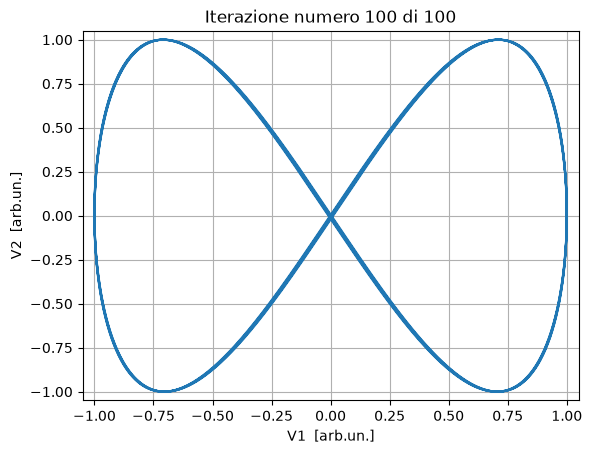

In [63]:
from IPython import display
import ipywidgets as widgets
import pylab as py
import numpy as np
from numpy import random
import time

# valori dei parametri (si possono cambiare, volendo!)
nofperiods = 5 # numero di periodi considerati
nofpoints = 5000 # numero di punti degli arrays
amplratio = 1.0 # rapporto tra le ampiezze V2/V1 (diverso da uno può migliorare la leggibilità)
deltaphi = 0.5 # valore dello sfasamento in pi rad
vardeltaphi = 0.01 # valore massimo dello sfasamento casuale in pi rad
freqratio = 2 # valore centrale di f2/f1
varfreqratio = 5e-2 # variazione massima relativa di f2/f1 attorno al valore centrale
numeropassi = 100 # numero dei passi del ciclo

# definisce le operazioni da compiere al lancio dello script
tarray = np.linspace(0, nofperiods,int(nofpoints)) # questo è l'array ancillare che rappresenta i tempi
V1 = np.cos(tarray*2*np.pi) # questa è la funzione V1
ii=0 # azzera la variabile ancillare ii

for i in range(1,numeropassi): # itera cambiando la frequenza in modo continuo 
    if (i<int(numeropassi/2)): # questo serve per andare indietro e poi tornare avanti con la frequenza
        ii=-i
    else:
        ii=i-int(numeropassi)
    freq=freqratio*(1+ii*varfreqratio/numeropassi) # qui viene definito il valore f2/f1 per ogni passo del ciclo
    sfasamento=deltaphi+np.random.rand()*vardeltaphi # qui viene tirato il dado per lo sfasamento
    V2 = amplratio*np.cos(tarray*2*np.pi*freq+sfasamento*np.pi) # questa è la funzione V2            
    py.plot(V1,V2) # disegna il grafico parametrico V2 vs V1
    py.xlabel('V1  [arb.un.]') # e questi sono i nomi degli assi
    py.ylabel('V2  [arb.un.]')
    py.xlim(-1.05,1.05) # qui fissa le scale
    py.ylim(-1.05,1.05)
    py.title('Iterazione numero '+str(i+1)+' di '+str(numeropassi)) # scrive nel titolo il numero di iterazione
    py.grid() # disegna una griglia per richiamare la graticola dell'oscilloscopio
    time.sleep(0.05) # aspetta un po' di tempo
    display.clear_output(wait=True) # ripulisce il grafico
    display.display(py.gcf()) # e lo ri-disegna
    py.close() # chiude le figure per evitare eccessivo consumo di memoria
    